# Baseline PoC: Weights of Evidence

**Цель:** получить первую воспроизводимую модель ранжирования перспективности ячеек для золота на Енисейском кряже.

**Данные:** 35 694 ячейки сетки 1×1 км, 11 известных месторождений, три признака: elevation, magnetic, gravity. Неизвестные ячейки не считаются достоверными отрицательными примерами.

**Метод:** Weights of Evidence (WoE) с квантильной дискретизацией признаков. Проверены конфигурации с 3 и 5 бинами.

**Валидация:** Spatial Block CV, 5 пространственных фолдов. Метрики: Precision@K и Success Rate для верхних 1%, 5% и 10% площади.

**Ограничения:** только 11 положительных объектов; отсутствие достоверных отрицательных примеров; возможная нестабильность WoE-весов; результаты зависят от пространственного разбиения.

## 1. Настройка окружения и параметры

In [31]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
SEED = 42
FEATURES = ["elevation", "magnetic", "gravity"]
TARGET = "is_deposit"
FOLD = "fold_id"

DATA_PATH = Path("../../data/processed/features_table.csv")

# Число квантильных интервалов для сравнения
BIN_COUNTS = [3, 5]
# сглаживание частот, чтобы избежать log(0)
ALPHA = 0.5
TOP_FRACTIONS = [0.01, 0.05, 0.10]

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {DATA_PATH.resolve()}\n"
    )

df = pd.read_csv(DATA_PATH)
print("Размерность:", df.shape)
print("Установленные месторождения:", int(df[TARGET].sum()))
print("Процент месторождений:", f"{df[TARGET].mean():.4%}")
display(df.head())

Размерность: (35694, 10)
Установленные месторождения: 11
Процент месторождений: 0.0308%


,x,y,latitude,longitude,is_deposit,deposit_name,fold_id,elevation,magnetic,gravity
0,459500.0,6485500.0,58.508188,92.304945,0,NaN,3,122.0,-176.118240,62.864227
1,459500.0,6486500.0,58.517168,92.304768,0,NaN,3,114.0,-180.356430,63.677711
2,459500.0,6487500.0,58.526149,92.304590,0,NaN,1,105.0,-184.596954,64.498230
3,459500.0,6488500.0,58.535129,92.304412,0,NaN,1,96.0,-188.797043,65.087418
4,459500.0,6489500.0,58.544110,92.304234,0,NaN,1,92.0,-192.825455,64.723465


## 2. Проверка данных

In [33]:
required = FEATURES + [TARGET, FOLD, "x", "y"]
missing_cols = sorted(set(required) - set(df.columns))
if missing_cols:
    raise ValueError(f"В таблице нет колонок: {missing_cols}")

if df[required].isna().any().any():
    display(df[required].isna().sum())
    raise ValueError("В необходимых колонках есть пропуски.")

if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("is_deposit должен содержать только 0/1.")

if df.duplicated(["x", "y"]).any():
    raise ValueError("Найдены дубликаты ячеек по x/y.")

print("Строки:", len(df))
print("Известные месторождения:", int(df[TARGET].sum()))
print("Уникальные месторождения:", df.loc[df[TARGET].eq(1), "deposit_name"].nunique()
      if "deposit_name" in df.columns else "deposit_name column absent")
print("\nРаспределение ячеек по фолдам:")
display(df.groupby(FOLD).size().rename("cells").to_frame())
print("\nРаспределение известных месторождений по фолдам:")
display(df.groupby(FOLD)[TARGET].sum().rename("deposits").to_frame())

Строки: 35694
Известные месторождения: 11
Уникальные месторождения: 11

Распределение ячеек по фолдам:


,cells
fold_id,
0,4874
1,7273
2,3359
3,17250
4,2938



Распределение известных месторождений по фолдам:


,deposits
fold_id,
0,1
1,2
2,2
3,5
4,1


## 3. Сводка признаков

elevation                                              magnetic  \
               count median        mean         std    min    max    count   
is_deposit                                                                   
0              35683  443.0  443.597091  126.212036   82.0  978.0    35683   
1                 11  489.0  495.636364  118.758808  284.0  691.0       11   

                                                                        \
                median        mean         std         min         max   
is_deposit                                                               
0          -154.093704 -110.040747  122.266733 -282.633392  384.205627   
1          -159.788986 -137.861605   42.956443 -182.796051  -61.041298   

           gravity                                                         
             count     median       mean        std        min        max  
is_deposit                                                                 
0            35683  59.544735  57.814987  12.424680   6.285794  92.698593  
1               11  57.012203  59.893701  12.048884  46.276077  86.448494

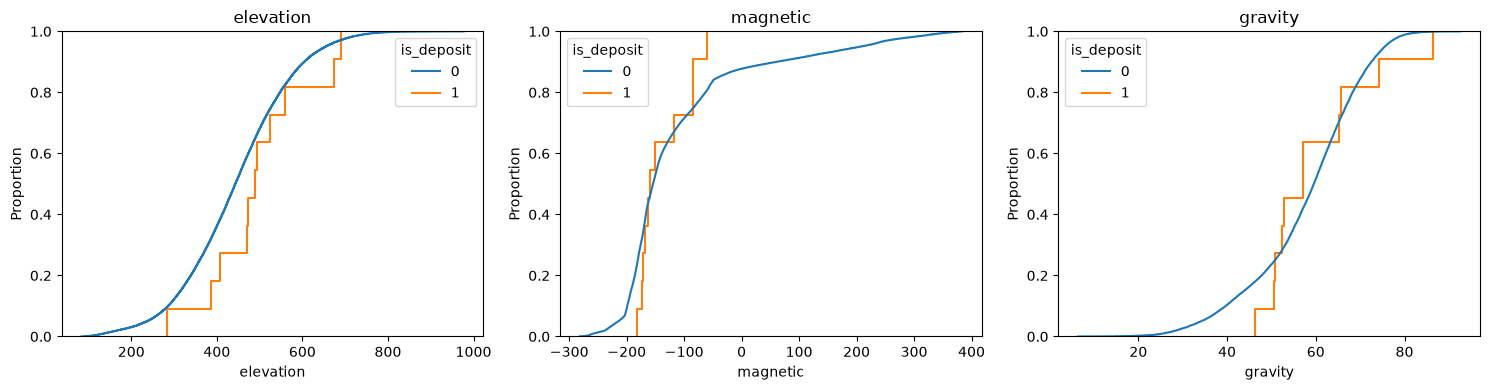

In [34]:
display(
    df.groupby(TARGET)[FEATURES]
      .agg(["count", "median", "mean", "std", "min", "max"])
)

fig, axes = plt.subplots(1, len(FEATURES), figsize=(15, 4))
for ax, feature in zip(axes, FEATURES):
    sns.ecdfplot(data=df, x=feature, hue=TARGET, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

## 4. WoE: определение

Для каждого интервала ($b$) признака считаем:

$$
W_b = \log\left(\frac{P(X \in b \mid \text{known deposit})}{P(X \in b \mid \text{unlabeled})}\right)
$$

Вероятности оцениваются по частотам с аддитивным сглаживанием `alpha`. Положительный вес означает, что интервал относительно чаще встречается у известных месторождений, чем на всей unlabeled-территории; отрицательный — реже.

**Ограничение PU:** unlabeled-группа может содержать неоткрытые месторождения. Поэтому это не классический WoE с достоверными отрицательными примерами и не оценка вероятности наличия золота. Также суммирование WoE нескольких признаков предполагает условную независимость свидетельств; корреляция magnetic–gravity у нас умеренная отрицательная, поэтому итоговую сумму следует считать приближённым ranking score.

## 5. Реализация WoE

In [35]:
def fit_woe(train, features, n_bins=5, alpha=0.5):
    """Обучает одномерные WoE-таблицы только на переданном train."""
    pos_mask = train[TARGET].eq(1)
    unl_mask = train[TARGET].eq(0)
    n_pos, n_unl = int(pos_mask.sum()), int(unl_mask.sum())

    if n_pos == 0 or n_unl == 0:
        raise ValueError("Для WoE нужны положительные и unlabeled ячейки.")

    model = {}

    for feature in features:
        _, edges = pd.qcut(
            train[feature], q=n_bins, retbins=True, duplicates="drop"
        )
        edges = np.unique(edges)
        if len(edges) < 3:
            raise ValueError(f"Недостаточно уникальных границ для {feature}")

        edges[0], edges[-1] = -np.inf, np.inf
        n_actual_bins = len(edges) - 1

        train_bins = pd.cut(train[feature], bins=edges, include_lowest=True)
        categories = train_bins.cat.categories

        pos_counts = (
            train_bins[pos_mask].value_counts(sort=False)
            .reindex(categories, fill_value=0)
        )
        unl_counts = (
            train_bins[unl_mask].value_counts(sort=False)
            .reindex(categories, fill_value=0)
        )

        p_pos = (pos_counts + alpha) / (n_pos + alpha * n_actual_bins)
        p_unl = (unl_counts + alpha) / (n_unl + alpha * n_actual_bins)
        weights = np.log(p_pos / p_unl)

        table = pd.DataFrame({
            "bin": categories.astype(str),
            "positive_count": pos_counts.to_numpy(),
            "unlabeled_count": unl_counts.to_numpy(),
            "p_bin_given_known_deposit": p_pos.to_numpy(),
            "p_bin_given_unlabeled": p_unl.to_numpy(),
            "woe": weights.to_numpy(),
        })

        model[feature] = {"edges": edges, "weights": weights, "table": table}

    return model


def score_woe(data, model):
    """Суммирует WoE по признакам; возвращает ranking score, не вероятность."""
    score = pd.Series(0.0, index=data.index, dtype=float)

    for feature, params in model.items():
        bins = pd.cut(
            data[feature],
            bins=params["edges"],
            include_lowest=True
        )
        mapped = bins.map(params["weights"]).astype(float)
        score = score.add(mapped, fill_value=0.0)

    return score

## 6. Обучение exploratory WoE на всей территории

Этот шаг нужен для изучения таблиц весов и предварительной карты. Он не является оценкой качества: все 11 известных месторождений участвуют в расчёте весов.

In [36]:
exploratory_models = {}
exploratory_scores = {}

for n_bins in BIN_COUNTS:
    model = fit_woe(df, FEATURES, n_bins=n_bins, alpha=ALPHA)
    score = score_woe(df, model)
    exploratory_models[n_bins] = model
    exploratory_scores[n_bins] = score

    print(f"\nWoE tables: {n_bins} bins")
    for feature in FEATURES:
        print(f"\nПризнак: {feature}")
        display(model[feature]["table"])

df["woe_score_exploratory_3bins"] = exploratory_scores[3]
df["woe_score_exploratory_5bins"] = exploratory_scores[5]

display(
    df.sort_values("woe_score_exploratory_3bins", ascending=False)[
        ["x", "y", TARGET, "deposit_name"] + FEATURES +
        ["woe_score_exploratory_3bins", "woe_score_exploratory_5bins"]
    ].head(20)
)


WoE tables: 3 bins

Признак: elevation


,bin,positive_count,unlabeled_count,p_bin_given_known_deposit,p_bin_given_unlabeled,woe
0,"(-inf, 391.0]",2,11982,0.20,0.335790,-0.518169
1,"(391.0, 495.0]",5,11836,0.44,0.331699,0.282548
2,"(495.0, inf]",4,11865,0.36,0.332511,0.079430



Признак: magnetic


,bin,positive_count,unlabeled_count,p_bin_given_known_deposit,p_bin_given_unlabeled,woe
0,"(-inf, -172.078]",2,11896,0.20,0.333380,-0.510966
1,"(-172.078, -119.33]",5,11893,0.44,0.333296,0.277744
2,"(-119.33, inf]",4,11894,0.36,0.333324,0.076989



Признак: gravity


...


Признак: magnetic


,bin,positive_count,unlabeled_count,p_bin_given_known_deposit,p_bin_given_unlabeled,woe
0,"(-inf, -185.728]",0,7139,0.037037,0.200067,-1.686735
1,"(-185.728, -166.479]",4,7135,0.333333,0.199955,0.511050
2,"(-166.479, -138.793]",3,7135,0.259259,0.199955,0.259735
3,"(-138.793, -62.891]",3,7136,0.259259,0.199983,0.259595
4,"(-62.891, inf]",1,7138,0.111111,0.200039,-0.587983



Признак: gravity


,bin,positive_count,unlabeled_count,p_bin_given_known_deposit,p_bin_given_unlabeled,woe
0,"(-inf, 47.803]",1,7138,0.111111,0.200039,-0.587983
1,"(47.803, 56.512]",4,7135,0.333333,0.199955,0.511050
2,"(56.512, 62.249]",2,7136,0.185185,0.199983,-0.076877
3,"(62.249, 68.273]",2,7137,0.185185,0.200011,-0.077017
4,"(68.273, inf]",2,7137,0.185185,0.200011,-0.077017


,x,y,is_deposit,deposit_name,elevation,magnetic,gravity,woe_score_exploratory_3bins,woe_score_exploratory_5bins
12657,514500.0,6611500.0,0,NaN,450.0,-169.694611,41.172653,0.838036,-0.154510
12658,514500.0,6612500.0,0,NaN,486.0,-169.243759,38.521740,0.838036,0.186594
12635,514500.0,6589500.0,0,NaN,435.0,-169.024628,51.953476,0.838036,0.944522
12656,514500.0,6610500.0,0,NaN,456.0,-170.067902,42.687008,0.838036,-0.154510
12869,515500.0,6589500.0,0,NaN,446.0,-168.614044,53.254337,0.838036,0.944522
12870,515500.0,6590500.0,0,NaN,462.0,-164.199615,50.544613,0.838036,0.693208
12871,515500.0,6591500.0,0,NaN,483.0,-159.786392,47.827770,0.838036,1.034312
12889,515500.0,6609500.0,0,NaN,481.0,-169.865402,41.146431,0.838036,0.186594
12890,515500.0,6610500.0,0,NaN,441.0,-169.710327,43.313992,0.838036,-0.154510
27975,580500.0,6499500.0,0,NaN,447.0,-169.393600,52.956184,0.838036,0.944522


## 7. Карта exploratory score

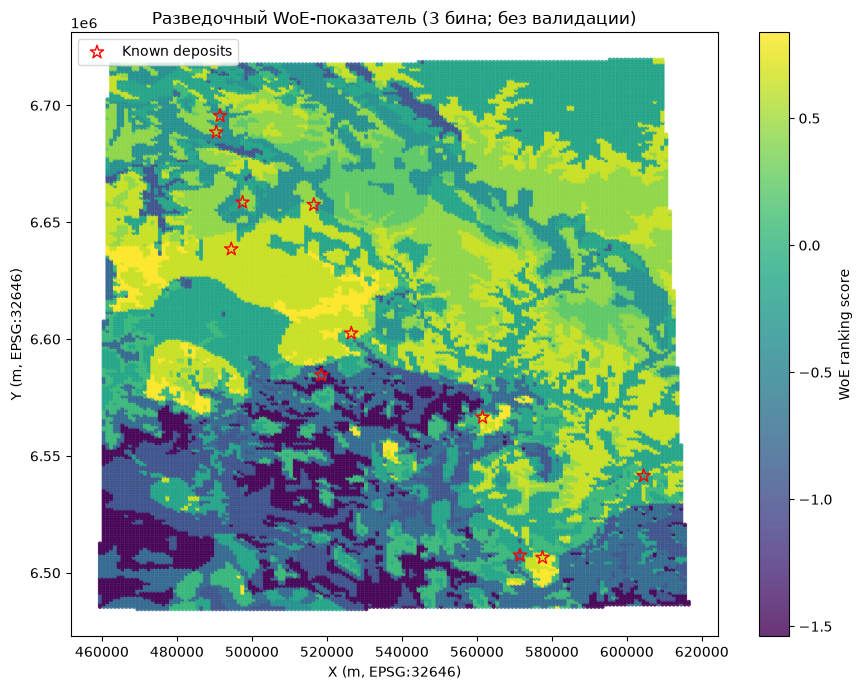

In [37]:
score_col = "woe_score_exploratory_3bins"

fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(
    df["x"], df["y"], c=df[score_col],
    s=5, cmap="viridis", alpha=0.8
)
dep = df[df[TARGET].eq(1)]
ax.scatter(dep["x"], dep["y"], marker="*", s=100,
           facecolors="none", edgecolors="red", label="Known deposits")
ax.set_xlabel("X (m, EPSG:32646)")
ax.set_ylabel("Y (m, EPSG:32646)")
ax.set_title("Разведочный WoE-показатель (3 бина; без валидации)")
ax.legend()
plt.colorbar(sc, ax=ax, label="WoE ranking score")
plt.tight_layout()
plt.show()

## 8. Анализ результата

Метрики

In [38]:
def ranking_metrics(y_true, scores, fractions=(0.01, 0.05, 0.10)):
    y = np.asarray(y_true, dtype=int)
    s = np.asarray(scores, dtype=float)
    n, n_pos = len(y), int(y.sum())

    if n_pos == 0:
        return pd.DataFrame([{
            "area_fraction": f, "top_k_cells": max(1, int(np.ceil(n*f))),
            "known_deposits_found": np.nan,
            "precision_at_k": np.nan, "success_rate": np.nan
        } for f in fractions])

    order = np.argsort(-s, kind="stable")
    y_sorted = y[order]
    rows = []
    for fraction in fractions:
        k = max(1, int(np.ceil(n * fraction)))
        found = int(y_sorted[:k].sum())
        rows.append({
            "area_fraction": fraction,
            "top_k_cells": k,
            "known_deposits_found": found,
            "precision_at_k": found / k,
            "success_rate": found / n_pos,
        })
    return pd.DataFrame(rows)


display(ranking_metrics(df[TARGET], df["woe_score_exploratory_3bins"], TOP_FRACTIONS))

,area_fraction,top_k_cells,known_deposits_found,precision_at_k,success_rate
0,0.01,357,0,0.00000,0.000000
1,0.05,1785,1,0.00056,0.090909
2,0.10,3570,1,0.00028,0.090909


Анализ score

In [39]:
for n_bins, scores in exploratory_scores.items():
    print(f"\n{n_bins} bins")
    print("Уникальных score:", scores.nunique())
    print("Всего ячеек:", len(scores))

    print("\nСамые частые score:")
    display(
        scores.value_counts()
              .head(10)
              .rename_axis("score")
              .reset_index(name="cells")
    )

for n_bins, scores in exploratory_scores.items():
    deposits = df.loc[df["is_deposit"].eq(1),
                      ["deposit_name", "x", "y", "fold_id"]].copy()
    deposits["score"] = scores.loc[deposits.index]

    print(f"\nИзвестные месторождения — {n_bins} bins")
    display(deposits.sort_values("score", ascending=False))

def inspect_cutoff_ties(y_true, scores, fractions=(0.01, 0.05, 0.10)):
    y = np.asarray(y_true)
    s = np.asarray(scores)
    rows = []

    for fraction in fractions:
        k = max(1, int(np.ceil(len(y) * fraction)))
        cutoff = np.sort(s)[::-1][k - 1]
        strictly_above = s > cutoff
        tied = s == cutoff

        rows.append({
            "area_fraction": fraction,
            "k": k,
            "cutoff_score": cutoff,
            "cells_strictly_above": int(strictly_above.sum()),
            "cells_tied_at_cutoff": int(tied.sum()),
            "deposits_strictly_above": int(y[strictly_above].sum()),
            "deposits_tied_at_cutoff": int(y[tied].sum()),
        })

    return pd.DataFrame(rows)

for n_bins, scores in exploratory_scores.items():
    print(f"\nНичьи на границе — {n_bins} bins")
    display(inspect_cutoff_ties(df["is_deposit"], scores))



3 bins
Уникальных score: 20
Всего ячеек: 35694

Самые частые score:


,score,cells
0,0.637281,3871
1,0.434163,3322
2,-1.540100,2809
3,-0.153792,2775
4,-0.952145,2506
5,-0.739384,2419
6,0.634918,2131
7,0.049326,2117
8,-0.163436,2111
9,-0.163436,1761



5 bins
Уникальных score: 95
Всего ячеек: 35694

Самые частые score:


,score,cells
0,-2.356208,1371
1,-1.768421,1236
2,0.105141,1139
3,0.446105,1097
4,0.098164,1043
5,0.451041,994
6,0.105001,881
7,0.446245,867
8,0.098024,798
9,-1.260520,769



Известные месторождения — 3 bins


...

,deposit_name,x,y,fold_id,score
27280,Vasilevskoye deposit,577500.0,6506500.0,3,1.285626
8004,Olimpiada Mine,494500.0,6638500.0,3,1.039248
13171,Eldorado deposit,516500.0,6657500.0,3,1.039107
23596,Konduyak Au deposit,561500.0,6566500.0,0,0.944522
13566,Veduga deposit,518500.0,6584500.0,1,0.697699
25877,Gerfed deposit,571500.0,6507500.0,3,0.697699
7118,Sovetskoe Au deposit,490500.0,6688500.0,2,0.098024
7359,Dobroe Au deposit,491500.0,6695500.0,2,0.098024
15456,Panimbinskoye deposit,526500.0,6602500.0,4,-0.059785
33631,Uderey deposit,604500.0,6541500.0,3,-0.409737



Ничьи на границе — 3 bins


,area_fraction,k,cutoff_score,cells_strictly_above,cells_tied_at_cutoff,deposits_strictly_above,deposits_tied_at_cutoff
0,0.01,357,0.838036,0,743,0,1
1,0.05,1785,0.637281,743,3871,1,0
2,0.10,3570,0.637281,743,3871,1,0



Ничьи на границе — 5 bins


,area_fraction,k,cutoff_score,cells_strictly_above,cells_tied_at_cutoff,deposits_strictly_above,deposits_tied_at_cutoff
0,0.01,357,1.285626,228,511,0,1
1,0.05,1785,1.034312,1667,329,3,0
2,0.10,3570,0.697699,3152,429,4,2


Подсчёт метрик с учётом ничьих

In [40]:
def tie_aware_ranking_metrics(
    y_true,
    scores,
    fractions=(0.01, 0.05, 0.10),
):
    y = np.asarray(y_true, dtype=int)
    s = np.asarray(scores, dtype=float)

    n = len(y)
    rows = []

    for fraction in fractions:
        k = max(1, int(np.ceil(n * fraction)))

        # Все ячейки, строго превосходящие граничный score
        cutoff = np.sort(s)[::-1][k - 1]
        above = s > cutoff
        tied = s == cutoff

        found_above = int(y[above].sum())
        positive_ties = int(y[tied].sum())

        n_slots = k - int(above.sum())
        n_tied = int(tied.sum())

        expected = (
            found_above
            + n_slots * positive_ties / n_tied
            if n_tied else found_above
        )

        rows.append({
            "area_fraction": fraction,
            "top_k_cells": k,
            "cutoff_score": cutoff,
            "found_min": found_above,
            "found_max": found_above + min(n_slots, positive_ties),
            "found_expected": expected,
            "success_rate_expected": expected / y.sum()
                if y.sum() else np.nan,
            "cells_tied_at_cutoff": n_tied,
        })

    return pd.DataFrame(rows)


for n_bins, scores in exploratory_scores.items():
    print(f"\nExploratory: {n_bins} bins")
    display(
        tie_aware_ranking_metrics(df["is_deposit"], scores)
    )


Exploratory: 3 bins


,area_fraction,top_k_cells,cutoff_score,found_min,found_max,found_expected,success_rate_expected,cells_tied_at_cutoff
0,0.01,357,0.838036,0,1,0.480485,0.043680,743
1,0.05,1785,0.637281,1,1,1.000000,0.090909,3871
2,0.10,3570,0.637281,1,1,1.000000,0.090909,3871



Exploratory: 5 bins


,area_fraction,top_k_cells,cutoff_score,found_min,found_max,found_expected,success_rate_expected,cells_tied_at_cutoff
0,0.01,357,1.285626,0,1,0.252446,0.022950,511
1,0.05,1785,1.034312,3,3,3.000000,0.272727,329
2,0.10,3570,0.697699,4,6,5.948718,0.540793,429


Проверка, где ошибается модель

In [41]:
def deposit_ranks_in_test_fold(test, scores):
    result = test.loc[
        test["is_deposit"].eq(1),
        ["deposit_name", "x", "y", "fold_id"]
    ].copy()

    scores = pd.Series(scores, index=test.index)
    result["score"] = scores.loc[result.index]

    # Ранг с учётом ничьих: одинаковый score получает одинаковый ранг.
    result["rank_min"] = result["score"].rank(
        ascending=False, method="min"
    ).astype(int)

    result["rank_percentile"] = (
        result["score"].rank(ascending=False, pct=True)
    )

    result["top_fraction"] = (
        result["rank_min"] / len(test)
    )

    return result.sort_values("rank_min")


for n_bins in [3, 5]:
    print(f"\n{n_bins} bins")

    for fold in sorted(df["fold_id"].unique()):
        train = df[df["fold_id"] != fold].copy()
        test = df[df["fold_id"] == fold].copy()

        model = fit_woe(
            train,
            FEATURES,
            n_bins=n_bins,
            alpha=ALPHA
        )
        scores = score_woe(test, model)

        print(
            f"Fold {fold}: "
            f"{int(test['is_deposit'].sum())} known deposits"
        )

        display(deposit_ranks_in_test_fold(test, scores))


3 bins
Fold 0: 1 known deposits


,deposit_name,x,y,fold_id,score,rank_min,rank_percentile,top_fraction
23596,Konduyak Au deposit,561500.0,6566500.0,0,0.847877,1,1.0,0.000205


Fold 1: 2 known deposits


,deposit_name,x,y,fold_id,score,rank_min,rank_percentile,top_fraction
8726,Blagodatnoe,497500.0,6658500.0,1,-0.339319,1,0.5,0.000137
13566,Veduga deposit,518500.0,6584500.0,1,-0.850145,2,1.0,0.000275


Fold 2: 2 known deposits


...

,deposit_name,x,y,fold_id,score,rank_min,rank_percentile,top_fraction
7118,Sovetskoe Au deposit,490500.0,6688500.0,2,-2.379148,1,0.75,0.000298
7359,Dobroe Au deposit,491500.0,6695500.0,2,-2.379148,1,0.75,0.000298


Fold 3: 5 known deposits


,deposit_name,x,y,fold_id,score,rank_min,rank_percentile,top_fraction
8004,Olimpiada Mine,494500.0,6638500.0,3,0.649637,1,0.2,0.000058
25877,Gerfed deposit,571500.0,6507500.0,3,0.487057,2,0.4,0.000116
27280,Vasilevskoye deposit,577500.0,6506500.0,3,0.138269,3,0.6,0.000174
13171,Eldorado deposit,516500.0,6657500.0,3,-0.960615,4,0.8,0.000232
33631,Uderey deposit,604500.0,6541500.0,3,-0.970622,5,1.0,0.000290


Fold 4: 1 known deposits


,deposit_name,x,y,fold_id,score,rank_min,rank_percentile,top_fraction
15456,Panimbinskoye deposit,526500.0,6602500.0,4,-1.267207,1,1.0,0.00034


Вклад каждого признака

In [42]:
for n_bins in [3, 5]:
    print(f"\n{n_bins} bins: вклад каждого признака")

    for feature in FEATURES:
        fold_results = []

        for fold in sorted(df["fold_id"].unique()):
            train = df[df["fold_id"] != fold].copy()
            test = df[df["fold_id"] == fold].copy()

            model = fit_woe(
                train,
                [feature],
                n_bins=n_bins,
                alpha=ALPHA
            )
            scores = score_woe(test, model)

            metrics = ranking_metrics(
                test["is_deposit"],
                scores,
                fractions=(0.05, 0.10)
            )

            metrics["fold_id"] = fold
            fold_results.append(metrics)

        print(f"\nПризнак: {feature}")
        display(pd.concat(fold_results, ignore_index=True))


3 bins: вклад каждого признака

Признак: elevation


,area_fraction,top_k_cells,known_deposits_found,precision_at_k,success_rate,fold_id
0,0.05,244,0,0.0,0.0,0
1,0.10,488,0,0.0,0.0,0
2,0.05,364,0,0.0,0.0,1
3,0.10,728,0,0.0,0.0,1
4,0.05,168,0,0.0,0.0,2
5,0.10,336,0,0.0,0.0,2
6,0.05,863,0,0.0,0.0,3
7,0.10,1725,0,0.0,0.0,3
8,0.05,147,0,0.0,0.0,4
9,0.10,294,0,0.0,0.0,4



Признак: magnetic


,area_fraction,top_k_cells,known_deposits_found,precision_at_k,success_rate,fold_id
0,0.05,244,0,0.000000,0.0,0
1,0.10,488,0,0.000000,0.0,0
2,0.05,364,0,0.000000,0.0,1
3,0.10,728,0,0.000000,0.0,1
4,0.05,168,0,0.000000,0.0,2
5,0.10,336,0,0.000000,0.0,2
6,0.05,863,1,0.001159,0.2,3
7,0.10,1725,1,0.000580,0.2,3
8,0.05,147,0,0.000000,0.0,4
9,0.10,294,0,0.000000,0.0,4



Признак: gravity


...

,area_fraction,top_k_cells,known_deposits_found,precision_at_k,success_rate,fold_id
0,0.05,244,0,0.00000,0.0,0
1,0.10,488,0,0.00000,0.0,0
2,0.05,364,0,0.00000,0.0,1
3,0.10,728,0,0.00000,0.0,1
4,0.05,168,0,0.00000,0.0,2
5,0.10,336,0,0.00000,0.0,2
6,0.05,863,0,0.00000,0.0,3
7,0.10,1725,1,0.00058,0.2,3
8,0.05,147,0,0.00000,0.0,4
9,0.10,294,0,0.00000,0.0,4



Признак: magnetic


,area_fraction,top_k_cells,known_deposits_found,precision_at_k,success_rate,fold_id
0,0.05,244,0,0.0,0.0,0
1,0.10,488,0,0.0,0.0,0
2,0.05,364,0,0.0,0.0,1
3,0.10,728,0,0.0,0.0,1
4,0.05,168,0,0.0,0.0,2
5,0.10,336,0,0.0,0.0,2
6,0.05,863,0,0.0,0.0,3
7,0.10,1725,0,0.0,0.0,3
8,0.05,147,0,0.0,0.0,4
9,0.10,294,0,0.0,0.0,4



Признак: gravity


,area_fraction,top_k_cells,known_deposits_found,precision_at_k,success_rate,fold_id
0,0.05,244,1,0.004098,1.0,0
1,0.10,488,1,0.002049,1.0,0
2,0.05,364,0,0.000000,0.0,1
3,0.10,728,0,0.000000,0.0,1
4,0.05,168,0,0.000000,0.0,2
5,0.10,336,0,0.000000,0.0,2
6,0.05,863,0,0.000000,0.0,3
7,0.10,1725,1,0.000580,0.2,3
8,0.05,147,0,0.000000,0.0,4
9,0.10,294,0,0.000000,0.0,4


## 9. Spatial Block CV: out-of-fold оценки

Для каждого фолда веса и границы бинов обучаются на остальных фолдах, затем скорятся только ячейки исключённого фолда. Метрики считаются внутри каждого тестового блока: из-за различного числа ячеек и всего 11 известных объектов результаты по фолдам будут шумными.

OOF score разных фолдов получен разными моделями, поэтому не следует безоговорочно ранжировать все OOF scores вместе: шкалы весов могут отличаться. Основной отчёт - метрики отдельно по тестовым фолдам и их абсолютные числа.

In [43]:
cv_rows = []
oof_parts = []

for n_bins in BIN_COUNTS:
    for fold in sorted(df[FOLD].unique()):
        train = df.loc[df[FOLD].ne(fold)].copy()
        test = df.loc[df[FOLD].eq(fold)].copy()

        if train[TARGET].sum() == 0:
            warnings.warn(f"Fold {fold}: в train нет известных месторождений.")
            continue

        model = fit_woe(train, FEATURES, n_bins=n_bins, alpha=ALPHA)
        test_scores = score_woe(test, model)

        metrics = ranking_metrics(
            test[TARGET], test_scores, TOP_FRACTIONS
        )
        metrics["n_bins"] = n_bins
        metrics["test_fold"] = fold
        metrics["test_cells"] = len(test)
        metrics["test_deposits"] = int(test[TARGET].sum())
        cv_rows.append(metrics)

        part = test[["x", "y", TARGET, FOLD]].copy()
        if "deposit_name" in test.columns:
            part["deposit_name"] = test["deposit_name"]
        part["n_bins"] = n_bins
        part["test_fold"] = fold
        part["woe_score_oof"] = test_scores
        oof_parts.append(part)

cv_results = pd.concat(cv_rows, ignore_index=True)
oof_scores = pd.concat(oof_parts, ignore_index=True)

display(
    cv_results.sort_values(["n_bins", "test_fold", "area_fraction"])
)

cv_summary = (
    cv_results.groupby(["n_bins", "area_fraction"])
    .agg(
        mean_precision_at_k=("precision_at_k", "mean"),
        mean_success_rate=("success_rate", "mean"),
        folds=("test_fold", "nunique"),
    )
    .reset_index()
)
display(cv_summary)

,area_fraction,top_k_cells,known_deposits_found,precision_at_k,success_rate,n_bins,test_fold,test_cells,test_deposits
0,0.01,49,0,0.0,0.0,3,0,4874,1
1,0.05,244,0,0.0,0.0,3,0,4874,1
2,0.10,488,0,0.0,0.0,3,0,4874,1
3,0.01,73,0,0.0,0.0,3,1,7273,2
4,0.05,364,0,0.0,0.0,3,1,7273,2
5,0.10,728,0,0.0,0.0,3,1,7273,2
6,0.01,34,0,0.0,0.0,3,2,3359,2
7,0.05,168,0,0.0,0.0,3,2,3359,2
8,0.10,336,0,0.0,0.0,3,2,3359,2
9,0.01,173,0,0.0,0.0,3,3,17250,5


,n_bins,area_fraction,mean_precision_at_k,mean_success_rate,folds
0,3,0.01,0.0,0.0,5
1,3,0.05,0.0,0.0,5
2,3,0.10,0.0,0.0,5
3,5,0.01,0.0,0.0,5
4,5,0.05,0.0,0.0,5
5,5,0.10,0.0,0.0,5


## 10. Success-Rate Curve по каждому тестовому фолду

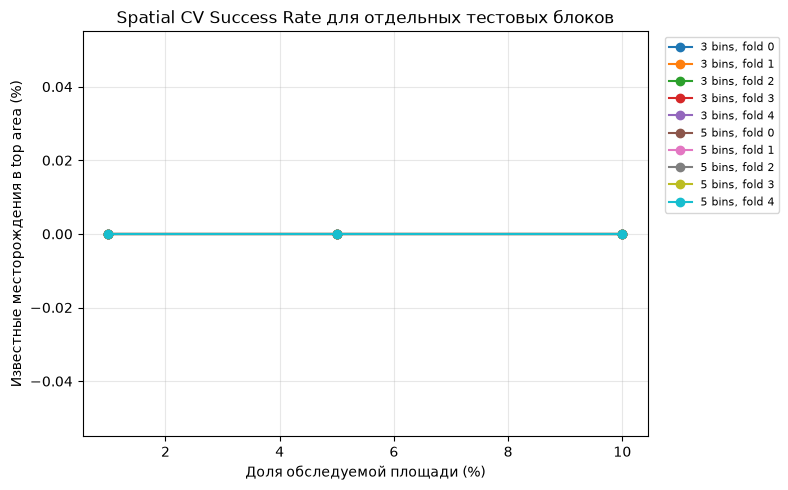

In [44]:
fig, ax = plt.subplots(figsize=(8, 5))

for (n_bins, fold), group in cv_results.groupby(["n_bins", "test_fold"]):
    group = group.sort_values("area_fraction")
    ax.plot(
        group["area_fraction"] * 100,
        group["success_rate"] * 100,
        marker="o",
        label=f"{n_bins} bins, fold {fold}"
    )

ax.set_xlabel("Доля обследуемой площади (%)")
ax.set_ylabel("Известные месторождения в top area (%)")
ax.set_title("Spatial CV Success Rate для отдельных тестовых блоков")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Сохранение результатов

In [45]:
OUTPUT_DIR = Path("../../data/processed/woe_baseline")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

exploratory_export = df[
    ["x", "y", TARGET, FOLD] + FEATURES +
    ["woe_score_exploratory_3bins", "woe_score_exploratory_5bins"]
].copy()
exploratory_export.to_parquet(
    OUTPUT_DIR / "exploratory_scores.parquet", index=False
)

cv_results.to_csv(OUTPUT_DIR / "spatial_cv_metrics.csv", index=False)
oof_scores.to_parquet(OUTPUT_DIR / "spatial_cv_oof_scores.parquet", index=False)

for n_bins, model in exploratory_models.items():
    for feature, params in model.items():
        params["table"].to_csv(
            OUTPUT_DIR / f"woe_table_{feature}_{n_bins}bins.csv",
            index=False
        )

print("Saved to:", OUTPUT_DIR.resolve())

Saved to: D:\Uni\Сборники\3 курс\Командная разработка\Удалённый репозиторий\data\processed\woe_baseline


## 12. Вывод

В текущей реализации на тестовых пространственных фолдах известные месторождения не попали в верхние 1%, 5% или 10% тестовых ячеек. На всей таблице конфигурация с 5 бинами ранжирует 3 месторождения в верхних 5% и 4 месторождения строго выше порога верхних 10%. Следовательно, качество обобщения baseline пока не подтверждено. Результат служит воспроизводимой отправной точкой для последующих этапов проекта, но не подтверждает пригодность модели для практического прогноза месторождений.